<a href="https://colab.research.google.com/github/murtaza-aiml/python_ai_ml/blob/main/Logistic_Regression_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Model Evaluation Results ===
Test Set Accuracy: 100.0%
Test Set Log Loss: 0.1894

=== Test Set Predictions ===
Age: 19 | Salary: $ 19,000 | Actual: 0 | Predicted: 0 (7.2% prob)
Age: 22 | Salary: $ 25,000 | Actual: 0 | Predicted: 0 (11.0% prob)
Age: 31 | Salary: $ 58,000 | Actual: 0 | Predicted: 0 (42.1% prob)
Age: 53 | Salary: $135,000 | Actual: 1 | Predicted: 1 (98.0% prob)

New Customer (Age 36, Salary $80k) -> Prediction: 1 (67.9% chance to buy)


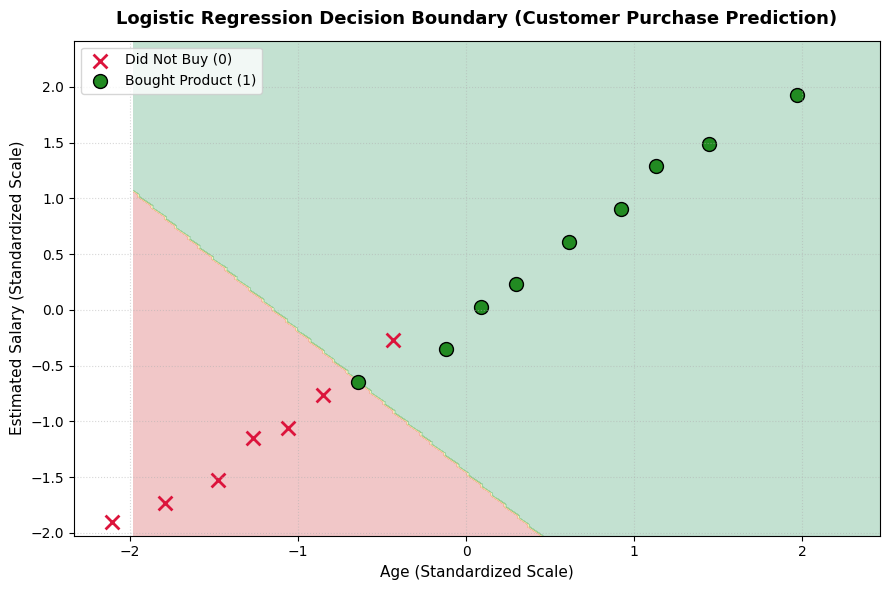

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# ==========================================
# === 1. COMPLETE CLASSIFICATION DATASET ===
# ==========================================
# 16 customers: Age & Estimated Salary -> Purchased (0 = No, 1 = Yes)
ages = [int(x) for x in "19,22,25,27,29,31,33,35,38,40,42,45,48,50,53,58".split(",")]
salaries = [float(x) for x in "19000,25000,32000,45000,48000,58000,62000,75000,72000,85000,92000,105000,115000,128000,135000,150000".split(",")]
purchased = [int(x) for x in "0,0,0,0,0,0,1,0,1,1,1,1,1,1,1,1".split(",")]

df = pd.DataFrame({
    'Age': ages,
    'Estimated_Salary': salaries,
    'Purchased': purchased
})

X = df[['Age', 'Estimated_Salary']]
y = df['Purchased']


# ==========================================
# === 2. TRAIN / TEST SPLIT              ===
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


# ==========================================
# === 3. FEATURE SCALING                 ===
# ==========================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ==========================================
# === 4. TRAIN LOGISTIC REGRESSION       ===
# ==========================================
clf = LogisticRegression()
clf.fit(X_train_scaled, y_train)


# ==========================================
# === 5. EVALUATE & PREDICT              ===
# ==========================================
y_pred = clf.predict(X_test_scaled)
y_probs = clf.predict_proba(X_test_scaled)

accuracy = clf.score(X_test_scaled, y_test)
loss = metrics.log_loss(y_test, y_probs)

print("=== Model Evaluation Results ===")
print(f"Test Set Accuracy: {accuracy * 100:.1f}%")
print(f"Test Set Log Loss: {loss:.4f}\n")

print("=== Test Set Predictions ===")
for i in range(len(X_test)):
    actual = y_test.iloc[i]
    guess = y_pred[i]
    prob_buy = y_probs[i][1] * 100
    print(f"Age: {X_test.iloc[i]['Age']:2.0f} | Salary: ${X_test.iloc[i]['Estimated_Salary']:7,.0f} | Actual: {actual} | Predicted: {guess} ({prob_buy:.1f}% prob)")

# Predict on a brand-new unseen customer (Age: 36, Salary: $80,000)
new_customer = pd.DataFrame([[36, 80000.0]], columns=['Age', 'Estimated_Salary'])
new_customer_scaled = scaler.transform(new_customer)
new_pred = clf.predict(new_customer_scaled)[0]
new_prob = clf.predict_proba(new_customer_scaled)[0][1] * 100

print(f"\nNew Customer (Age 36, Salary $80k) -> Prediction: {new_pred} ({new_prob:.1f}% chance to buy)")


# ==========================================
# === 6. MATPLOTLIB VISUALIZATION        ===
# ==========================================
# Create a dense grid across the entire scaled graph area to color the decision regions
x_min, x_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
y_min, y_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict class (0 or 1) for every single pixel on the background grid
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))

# Shade the background regions (Red zone = Predict 0, Green zone = Predict 1)
plt.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.RdYlGn)

# Plot the actual customer data points on top of the shaded zones
did_not_buy = df[df['Purchased'] == 0]
bought = df[df['Purchased'] == 1]

# Scale the full dataset just for plotting alignment
X_all_scaled = scaler.transform(X)
df['Age_Scaled'] = X_all_scaled[:, 0]
df['Salary_Scaled'] = X_all_scaled[:, 1]

plt.scatter(df[df['Purchased'] == 0]['Age_Scaled'], df[df['Purchased'] == 0]['Salary_Scaled'],
            color='crimson', marker='x', s=100, linewidths=2, label='Did Not Buy (0)')

plt.scatter(df[df['Purchased'] == 1]['Age_Scaled'], df[df['Purchased'] == 1]['Salary_Scaled'],
            color='forestgreen', marker='o', s=100, edgecolor='black', label='Bought Product (1)')

plt.title('Logistic Regression Decision Boundary (Customer Purchase Prediction)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Age (Standardized Scale)', fontsize=11)
plt.ylabel('Estimated Salary (Standardized Scale)', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()
